# Basics of Mobile Robotics - Project

## Table of Contents

- [Introduction](#introduction)
    - [Goal of the project](#goal-of-the-goal-of-the-project)
    - [Group](#group) 
    - [Demo](#demo)
- [Vision Processing](#vision-processing)
    - [Calibration](#calibration)
        - [Calibration parameters](#calibration-parameters)
        - [Process](#process)
        - [Implementation](#implementation)
    - [ArUco Markers](#aruco-markers)
        - [Implementation](#implementation-1)
    - [Bird's-Eye View Transformation](#birds-eye-view-transformation)
        - [Implementation](#implementation-2)
    - [Obstacle Mapping](#obstacle-mapping)
        - [Processing Pipeline](#processing-pipeline)
        - [Implementation](#implementation-3)
    - [Frame Capture](#frame-capture)
- [Filtering](#filtering)
    - [Extended Kalman Filter Overview](#extended-kalman-filter-overview)
    - [Prediction Step](#prediction-step)
    - [Update Step](#update-step)
    - [Coordinate Transformations](#coordinate-transformations)
- [Navigation](#navigation)
    - [Global Navigation](#global-navigation)
        - [A* Path Planning](#a-path-planning)
        - [Path Smoothing](#path-smoothing)
        - [Path Following](#path-following)
        - [Implementation](#implementation-4)
    - [Local Navigation](#local-navigation)
        - [Braitenberg-Inspired Controller](#braitenberg-inspired-controller)
        - [Sensor Fusion](#sensor-fusion)
        - [Motor Command Generation](#motor-command-generation)
- [Results](#results)
- [Conclusion](#conclusion)

## Introduction 
This project is part of the course *Basics of Mobile Robotics (MICRO-452)* at EPFL and is usually carried out by group of four students. The class is taught by Professor Francesco Mondada from the [MOBOTS lab](https://www.epfl.ch/labs/mobots/). This project aims to develop the basics of autonomous navigation on the [Thymio robot](https://learn.epfl.ch/initiatives/thymio/) by implementing various algorithms covered in the course.

### Goal of the project 
The main objectives of this project are the following:
- Autonomous navigation toward a specific goal by following the optimal path. 
- Tracking the goal even when it is not directly visible using an Extended Kalman Filter. 
- Reaching any position in the predefined map.
- Avoiding unexpected obstacles.


### Group
Our team consists of three first-year Master's students in Robotics at EPFL. The workload has been equally separated between members. The final assembly of the code has been done by everyone. 
| Name            | SCIPER | Role                       |
|-----------------|--------|----------------------------|
| Linus  Crugnola | 340864 | Filtering                  |
| Alexis Bollack  | 406474 | Local & Global navigation  |
| Maxime Luyet    | 345770 | Vision                     |

### Design choices 
Concerning each part of the project, specific choices were made to reach the fixed objectives:

**Localisation** 
- ArUco markers for positioning:
    - Used for map cropping, defining the working area
    - Robot positioning and orientation tracking 
    - Goal positioning 

**Map** 
- Obstacles have no shape restrictions
- Obstacles must be dark on a white background 
- Global dimensions of the map are fixed (95 cm × 60 cm) and contained on A0 paper
- Obstacles are modular, not fixed on the paper

**Path planning methods** 
- Use of cost grid defined by the camera resolution
- Collision avoidance is guaranteed by extension of obstacles in the occupancy grid
- The optimal path is computed following the A* algorithm with 8-connected neighbors and diagonal movement costs
- Path smoothing is applied to remove unnecessary waypoints using line-of-sight checks

**Navigation** 
- **Global navigation**: A* path planning on the occupancy grid from start to goal
- **Local navigation**: Braitenberg-inspired controller using 7 proximity sensors
    - Weighted direction vectors oppose detected obstacles
    - Includes short-term memory (neurons x8, x9) to prevent oscillations
    - Combines repulsion forces from sensors to compute avoidance direction
- **State estimation**: Extended Kalman Filter (EKF) for robot pose tracking
    - Prediction step using differential drive motion model (wheel speeds)
    - Update step using camera measurements (ArUco marker detection)
    - 3-state vector: (x, y, θ) with covariance matrices for process and measurement noise

### Demo 
Here you can see a video of the final result. The Thymio successfully reaches the goal while navigating through obstacles. He also keed track of the path even when blinded due to Kalman filtering. The Thymio is also able to reconise when he is kidnapped and recompute the optimal path. 

<video width="800" controls>
  <source src="img/Mobile_robotic_project_T41_demo.mp4" type="video/mp4">
  Your browser does not support the video tag.
</video>

**Video Elements Explanation:**

**Yellow Point** – Represents the current robot center position. When the ArUco marker (ID 78) is visible, the position is updated from the vision system; otherwise, it is estimated by the Extended Kalman Filter (EKF) during occlusion periods.

**Pink Point** – Shows the orthogonal projection of the robot's position onto the planned path. This closest point on the path serves as the reference for computing the lookahead target point used by the pure pursuit controller.

**Orange Point** – Indicates the current target point for the robot, positioned approximately 10 cm ahead along the path. The robot continuously steers toward this dynamic target to follow the smoothed trajectory.

**Gray Shadows (Cost Map)** – Visualizes the safety margins around obstacles. These zones represent dilated obstacles with a safety buffer of approximately 6.5 cm (robot radius), ensuring collision avoidance. The dilation process uses an elliptical structuring element, which explains why sharp obstacle corners appear rounded in the cost map. The gradient intensity indicates proximity to obstacles, guiding the path planner to maintain safe distances.

## Vision processing
The goal of this module is to provide real-time visual information to the navigation system. It is responsible for initializing an occupancy grid used to compute an A* optimal path in the *global_nav* module. To achieve this, the vision module must go through several stages:

1. Acquire a frame from the camera.
2. Compute a bird's-eye view (perpendicular top-down projection) of the environment using ArUco markers.
3. Detect obstacles and initialize the occupancy grid.
4. Extract the robot and goal positions.

To structure this, the system is divided into two classes: Camera and Vision.
This separation allows dedicated handling of the camera stream on one side, and all computer-vision operations on the other. It also improves the clarity of the architecture by isolating specific methods and attributes, ensuring better modularity and encapsulation.

Before implementing these classes, several essential tasks were required, such as camera calibration and ArUco marker generation, both of which are necessary to ensure accurate mapping, detection, and geometric transformations.

### Calibration
The calibration process allows us to obtain the intrinsic parameters of the camera in order to correct lens distortion. To perform this step, we used the [OpenCV](https://docs.opencv.org/4.x/dc/dbb/tutorial_py_calibration.html) library. 

The method consists of capturing several images of a calibration pattern (typically a chessboard), detecting its corner points, and using these correspondences to estimate how the camera projects 3D points onto the 2D image plane.

#### Calibration parameters  
**Distortion coefficients** are a vector containing: 
- Radial distortion ($k_1$, $k_2$, $k_3$)
- Tangential distortion ($p_1$, $p_2$)

$$D = \begin{pmatrix} k_1 & k_2 & p_1 & p_2 & k_3 \end{pmatrix}$$

**Calibration matrix** is a correction matrix made of intrinsic parameters of the camera: 
- Focal distances ($f_x$, $f_y$)
- Optical center ($c_x$, $c_y$)

$$M = \begin{pmatrix} f_x & 0 & c_x \\ 0 & f_y & c_y \\ 0 & 0 & 1 \end{pmatrix}$$

#### Process

OpenCV provides all the required tools for this workflow:

[`cv2.findChessboardCorners()`](https://docs.opencv.org/4.x/d9/d0c/group__calib3d.html#ga93efa9b0aa890de240ca32b11253dd4a) – Detects the inner intersections of the chessboard pattern in each calibration image.

[`cv2.cornerSubPix()`](https://docs.opencv.org/4.x/dd/d1a/group__imgproc__feature.html#ga354e0d7c86d0d9da75de9b9701a9a87e) – Refines the detected corner positions to sub-pixel accuracy for better calibration precision.

[`cv.drawChessboardCorners()`](https://docs.opencv.org/4.x/d9/d0c/group__calib3d.html#ga6a10b0bb120c4907e5eabbcd22319022) – Alternative function allowing to visualize the corner detection. 

[`cv2.calibrateCamera()`](https://docs.opencv.org/4.x/d9/d0c/group__calib3d.html#ga3207604e4b1a1758aa66acb6ed5aa65d) – Computes the intrinsic matrix, distortion coefficients (k₁, k₂, p₁, p₂, k₃), and optionally the rotation and translation vectors of the camera.

[`cv2.getOptimalNewCameraMatrix()`](https://docs.opencv.org/4.x/d9/d0c/group__calib3d.html#ga3207604e4b1a1758aa66acb6ed5aa65d) – Produces an adjusted projection matrix that balances field of view and distortion removal.

[`cv2.undistort()`](https://docs.opencv.org/4.x/d9/d0c/group__calib3d.html#ga69f2545a8b62a6b0fc2ee060dc30559d) – Uses the computed parameters to remove lens distortion from any captured frame.

This calibration procedure provides the intrinsic matrix and distortion vector used in the module to undistort the input frames before extracting ArUco markers and computing the bird's-eye-view transformation.

#### Implementation

The method `vision.setup()` implements the image distortion correction using the intrinsic parameters obtained after the calibration process:

```python 
h, w = frame.shape[:2]
newcameramtx, roi = cv2.getOptimalNewCameraMatrix(CAMERA_MATRIX, CAMERA_COEFFICIENTS, (w, h), 1, (w, h))
self.distortion = newcameramtx
self.roi = roi
frame = cv2.undistort(frame, CAMERA_MATRIX, CAMERA_COEFFICIENTS, None, self.distortion)
x, y, w, h = self.roi
frame = frame[y:y+h, x:x+w]
```

### ArUco Markers

ArUco markers are binary square fiducial markers that can be used for camera pose estimation and object tracking. For this project, we use the **4x4_100 dictionary** from OpenCV, which provides 100 unique markers in a 4×4 grid format. Each marker is 10×10 cm in size and printed at 300 DPI (591×591 pixels) on an A0 paper that defines the working area.

All markers were generated using the script `aruco_generation.py`, following the [OpenCV ArUco detection guide](https://docs.opencv.org/4.x/d5/dae/tutorial_aruco_detection.html).

The system uses six specific markers for different purposes:

**Map Corner Markers** (define the working area):
- **ID 69**: Top-left corner
- **ID 42**: Top-right corner  
- **ID 23**: Bottom-left corner
- **ID 30**: Bottom-right corner

**Dynamic Markers** (track moving elements):
- **ID 78**: Robot marker (attached to the Thymio)
- **ID 53**: Goal marker (target position)

These markers enable the vision system to:
1. Establish a fixed reference frame using the four corner markers.
2. Compute the perspective transformation for the bird's-eye view.
3. Track the robot's position and orientation in real-time.
4. Identify the goal location for path planning.

![Map with ArUco markers](scripts/aruco_markers/img/map_img.png)

#### Implementation 

The ArUco detection system is initialized in the `Vision` class constructor. This setup creates the detector with the appropriate dictionary and parameters:

```python 
def __init__(self):
    # Initialize ArUco dictionary and detector
    self.aruco_dict = cv2.aruco.getPredefinedDictionary(cv2.aruco.DICT_4X4_100)
    self.param = cv2.aruco.DetectorParameters()
    self.detector = cv2.aruco.ArucoDetector(self.aruco_dict, self.param)
```

The detector is then used throughout the vision pipeline to identify markers in each frame and extract their positions and orientations for coordinate transformations and tracking.

### Bird's-Eye View Transformation

To obtain an accurate occupancy grid, a **bird's-eye view** (top-down perpendicular projection) of the map is required. This transformation corrects perspective distortion using the four corner ArUco markers as reference points. The implementation follows the [OpenCV geometric transformations guide](https://docs.opencv.org/4.x/da/d6e/tutorial_py_geometric_transformations.html).

#### Implementation

The perspective transformation is implemented through two key steps:

1. **Compute the transformation matrix** using `_get_transform_matrix(corners_dict, width_px, height_px)`:
   - Defines source points from the detected corner marker positions in the camera frame
   - Defines destination points as a perfect rectangle in the output image
   - Computes the transformation matrix using [`cv2.getPerspectiveTransform()`](https://docs.opencv.org/4.x/da/d54/group__imgproc__transform.html#ga20f62aa3235d869c9956436c870893ae)

2. **Apply the transformation** using [`cv2.warpPerspective()`](https://docs.opencv.org/4.x/da/d54/group__imgproc__transform.html#gaf73673a7e8e18ec6963e3774e6a94b87):
   - Warps the input frame according to the computed matrix
   - Produces a perfectly perpendicular view of the map

Both operations are performed in the `vision.setup()` method during the initial configuration of the vision system. This setup ensures that all subsequent processing operates on geometrically corrected images, which is essential for accurate obstacle detection and robot localization. 

![Map illustration before and after point of view correction](img/before_after_point_of_view_correction.png) 

### Obstacle Mapping

Once the bird's-eye view is obtained, the system generates an **occupancy grid** (cost map) to represent obstacles in the environment. This grid is used by the global navigation module to compute the optimal A* path. The obstacle detection pipeline follows the [OpenCV image processing tutorials](https://docs.opencv.org/4.x/d2/d96/tutorial_py_table_of_contents_imgproc.html) and implements a multi-step approach.

#### Processing Pipeline

**Processing Steps:**

1. **Grayscale conversion** – [`cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)`](https://docs.opencv.org/3.4/d8/d01/group__imgproc__color__conversions.html) – Simplifies the image for processing.

2. **Gaussian blur** – [`cv2.GaussianBlur(gray, (9, 9), 0)`](https://docs.opencv.org/4.x/d4/d86/group__imgproc__filter.html#gaabe8c836e97159a9193fb0b11ac52cf1) – Reduces noise with a 9×9 kernel.

3. **Adaptive thresholding** – [`cv2.adaptiveThreshold(blurred, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY_INV, 11, 2)`](https://docs.opencv.org/4.x/d7/d1b/group__imgproc__misc.html#ga72b913f352e4a1b1b397736707afcde3) – Separates obstacles (white) from free space (black) using local intensity thresholds with an 11×11 neighborhood. Adaptive thresholding was chosen over Otsu's method because the controlled lighting conditions provide relatively stable illumination across the map, making the computationally lighter adaptive approach sufficient while maintaining robust obstacle detection.

4. **Corner masking** – Applies black rectangular masks at the four corners to remove ArUco markers that appear as obstacles. Each mask covers the marker area (10 cm) plus a 2 cm margin:
```python
if is_marker_in_corners:
    mask_size_px = int((ARUCO_SIZE_CM + 2.0) * self.pixels_per_cm)
    color = 0  # Black = free space
    h, w = binary.shape
    # Apply masks at all four corners
    cv2.rectangle(binary, (0, 0), (mask_size_px, mask_size_px), color, -1)  # Top-Left
    cv2.rectangle(binary, (w - mask_size_px, 0), (w, mask_size_px), color, -1)  # Top-Right
    cv2.rectangle(binary, (0, h - mask_size_px), (mask_size_px, h), color, -1)  # Bottom-Left
    cv2.rectangle(binary, (w - mask_size_px, h - mask_size_px), (w, h), color, -1)  # Bottom-Right
```

5. **Morphological operations** – [`cv2.morphologyEx(binary, cv2.MORPH_OPEN, kernel)`](https://docs.opencv.org/4.x/d9/d61/tutorial_py_morphological_ops.html) followed by [`cv2.MORPH_CLOSE`](https://docs.opencv.org/4.x/d9/d61/tutorial_py_morphological_ops.html) – Removes small noise with opening, then closes small gaps with closing, using a 3×3 kernel.

6. **Obstacle filling** – [`cv2.findContours(cleaned, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)`](https://docs.opencv.org/4.x/d3/dc0/group__imgproc__shape.html#gadf1ad6a0b82947fa1fe3c3d497f260e0) and [`cv2.drawContours(cleaned, contours, -1, 255, thickness=-1)`](https://docs.opencv.org/4.x/d6/d6e/group__imgproc__draw.html#ga746c0625f1781f1ffc9056259103edbc) – Detects external contours and fills all holes inside obstacles.

7. **Safety margin dilation** – [`cv2.dilate(cleaned, kernel_dilate, iterations=1)`](https://docs.opencv.org/4.x/d4/d86/group__imgproc__filter.html#ga4ff0f3318642c4f469d0e11f242f3b6c) – Expands obstacles by the robot's radius (6.5 cm) using an elliptical structuring element to create a safety buffer.

8. **Distance transform** – [`cv2.distanceTransform(inv_dilated, cv2.DIST_L2, 5)`](https://docs.opencv.org/4.x/d7/d1b/group__imgproc__misc.html#ga8a0b7fdfcb7a13dde018988ba3a43042) – Computes the Euclidean distance from each pixel to the nearest obstacle, creating a gradient cost map with a 7 cm fading zone.

9. **Cost map generation** – [`cv2.max(dilated, fading_border)`](https://docs.opencv.org/4.x/d2/de8/group__core__array.html#gacc40fa15eac0fb83f8ca70b7cc0b588e) – Combines hard obstacles with the distance gradient to produce the final cost map.

10. **Border safety** – [`cv2.rectangle(cost_map, (0, 0), (w-1, h-1), 255, border_thickness)`](https://docs.opencv.org/4.x/d6/d6e/group__imgproc__draw.html#ga07d2f74cadcf8e305e810ce8eed13bc9) – Adds a border around the entire map with thickness equal to the robot's width (13 cm) to prevent edge collisions.

**Visual Pipeline:**

| Grayscale | Gaussian Blur | Adaptive Threshold | Corner Mask | Morphological Operations |
|:---------:|:-------------:|:------------------:|:-----------:|:------------------------:|
| ![](img/Occupancy_Grid_1_Grayscale.png) | ![](img/Occupancy_Grid_2_Blurred.png) | ![](img/Occupancy_Grid_3_Binary.png) | ![](img/Occupancy_Grid_4_Cleaned.png) | ![](img/Occupancy_Grid_5_Cleaned_Morphology.png) |

| Obstacle Filling | Dilation | Fading Gradient | Cost Map | Final Cost Map + Border |
|:----------------:|:--------:|:---------------:|:--------:|:-----------------------:|
| ![](img/Occupancy_Grid_6_Holes_Filled.png) | ![](img/Occupancy_Grid_7_Dilated.png) | ![](img/Occupancy_Grid_8_Fading_Border.png) | ![](img/Occupancy_Grid_9_Cost_Map.png) | ![](img/Occupancy_Grid_10_Cost_Map_with_Border.png) |

#### Implementation

The complete obstacle detection is implemented in the `get_occupancy_grid()` method. This produces a **cost map** where pixel intensity represents traversal cost: 255 (white) indicates hard obstacles, 0 (black) represents free space, and intermediate values (gradient zones) guide the path planner to avoid obstacle edges while maintaining safety margins.

### Frame Capture

To ensure fast and efficient frame acquisition, the camera stream runs in a separate background thread. This design prevents the main control loop from blocking during frame capture operations, which typically take 30-50 ms per frame. Without threading, these delays would introduce timing jitter that could destabilize the control system.

**Thread Architecture:**

The `Camera` class implements a producer-consumer pattern where:
- A **background thread** continuously captures frames from the camera
- The **main thread** consumes the most recent frame on demand

This decoupling ensures the control loop always has access to fresh frames without waiting for I/O operations.

**Key Methods:**

**1. Constructor (`__init__`)** – Initializes the camera and launches the capture thread:

```python
def __init__(self, cam_id=0):
    self.cam_id = cam_id
    self.cap = cv2.VideoCapture(self.cam_id)
    
    if not self.cap.isOpened():
        print(f"Error: Unable to open camera with ID {self.cam_id}")
        self.cap = None
        self.running = False
        return
    
    # Capture initial frame
    self.ret, self.frame = self.cap.read()
    self.running = True
    
    # Launch daemon thread for continuous capture
    threading.Thread(target=self.update, args=(), daemon=True).start()
    print("Camera thread launched")
```

The `daemon=True` flag ensures the thread terminates automatically when the main program exits, preventing orphaned processes.

**2. Update Loop (`update`)** – Runs continuously in the background thread:

```python
def update(self):
    while self.running:
        self.ret, self.frame = self.cap.read()
```

This method constantly refreshes `self.frame` with the latest camera image. The `ret` boolean indicates whether frame capture was successful.

**3. Frame Access (`get_frame`)** – Provides thread-safe access to the latest frame:

```python
def get_frame(self):
    return self.ret, self.frame
```

Returns the most recent frame without blocking. While not explicitly protected by a mutex, this is safe in Python due to the Global Interpreter Lock (GIL), which ensures atomic reference assignments.

**4. Cleanup (`stop`)** – Safely releases camera resources:

```python
def stop(self):
    self.running = False
    if self.cap is not None:
        self.cap.release()
        print(f"Camera with ID {self.cam_id} released, thread stopped")
```

Sets the termination flag and releases the camera device.
This architecture achieves approximately 30 FPS frame access with negligible impact on the main control loop, enabling responsive real-time navigation and localization.

## Filtering

The filtering module implements an **Extended Kalman Filter (EKF)** for robust robot state estimation. The EKF fuses two complementary information sources to maintain accurate pose tracking even when visual measurements are unavailable:

- **Motion model (prediction)**: Uses wheel odometry to propagate the state forward
- **Vision system (update)**: Corrects predictions using ArUco marker detections

This probabilistic approach is essential for handling sensor noise and maintaining localization during marker occlusions.

### Extended Kalman Filter Overview

The robot state is represented as a 3-dimensional vector:

$$\mathbf{x} = \begin{pmatrix} x \\ y \\ \theta \end{pmatrix}$$

where $(x, y)$ is the position in millimeters and $\theta$ is the orientation in radians.

The EKF maintains two key quantities:
- **State estimate** $\mathbf{x}_k$: Best estimate of the robot pose at time $k$
- **Covariance matrix** $\mathbf{P}_k$ (3×3): Uncertainty in the state estimate

**Noise models:**
- **Process noise covariance** $\mathbf{Q}$ (2×2): Models uncertainty in wheel speeds
- **Measurement noise covariance** $\mathbf{R}$ (3×3): Models camera measurement noise

```python
# Configuration parameters
Q = np.eye(2) * 25        # Wheel odometry noise
R = np.eye(3) * 1         # Camera noise (x, y)
R[2, 2] = 1.2             # Higher uncertainty for orientation
WHEEL_BASE = 94           # Distance between wheels (mm)
```

### Prediction Step

The **prediction step** uses the differential drive motion model to propagate the state forward based on wheel speeds. This step is implemented in the `predict()` method.

**Motion Model Equations:**

Given wheel speeds $v_r$ (right) and $v_l$ (left) over time interval $\Delta t$:

1. **Compute velocities:**

$$v_{\text{lin}} = \frac{v_r + v_l}{2}$$

$$v_{\text{ang}} = \frac{v_r - v_l}{L}$$

where $L = 94$ mm is the wheel base.

2. **State propagation (non-linear model):**

$$x_{k+1} = x_k + v_{\text{lin}} \cos(\theta_k) \Delta t$$

$$y_{k+1} = y_k + v_{\text{lin}} \sin(\theta_k) \Delta t$$

$$\theta_{k+1} = \theta_k + v_{\text{ang}} \Delta t$$

3. **Covariance propagation (linearized):**

$$\mathbf{P}_{k+1} = \mathbf{F}_x \mathbf{P}_k \mathbf{F}_x^T + \mathbf{F}_u \mathbf{Q} \mathbf{F}_u^T$$

**Jacobian Matrices** (computed by `_linearize_motion()`):

$$\mathbf{F}_x = \frac{\partial f}{\partial \mathbf{x}} = \begin{pmatrix} 
1 & 0 & -v_{\text{lin}} \Delta t \sin(\theta) \\ 
0 & 1 & v_{\text{lin}} \Delta t \cos(\theta) \\ 
0 & 0 & 1 
\end{pmatrix}$$

These Jacobians linearize the non-linear motion model around the current state, enabling the EKF to propagate uncertainty correctly.

**Key implementation detail:**

```python
# Angle normalization to [-π, π]
self.x[2] = (self.x[2] + np.pi) % (2 * np.pi) - np.pi
```

This ensures orientation remains within the canonical range, preventing discontinuities.

### Update Step

The **update step** (also called correction step) incorporates camera measurements to correct the predicted state. This step is implemented in the `update()` method and follows the standard Kalman filter equations.

**Update Equations:**

1. **Innovation (measurement residual):**

$$\mathbf{y} = \mathbf{z}_k - \mathbf{x}_k$$

where $\mathbf{z}_k$ is the camera measurement and $\mathbf{x}_k$ is the predicted state.

2. **Kalman Gain:**

$$\mathbf{K} = \mathbf{P}_k (\mathbf{P}_k + \mathbf{R})^{-1}$$

The Kalman gain determines the optimal weighting between prediction and measurement:
- If $\mathbf{P}_k$ is large (high prediction uncertainty) → $\mathbf{K} \approx \mathbf{I}$ → trust measurement
- If $\mathbf{R}$ is large (noisy measurement) → $\mathbf{K} \approx 0$ → trust prediction

3. **State correction:**

$$\mathbf{x}_k = \mathbf{x}_k + \mathbf{K} \mathbf{y}$$

4. **Covariance correction:**

$$\mathbf{P}_k = (\mathbf{I} - \mathbf{K}) \mathbf{P}_k$$

The covariance decreases after each measurement, reflecting increased confidence in the state estimate.

**Operational Logic:**

```python
# Main control loop pattern
while robot_running:
    # Always predict (using odometry)
    ekf.predict(right_speed, left_speed, dt)
    
    # Update only when marker is visible
    if marker_detected:
        ekf.update(camera_pose)
    
    # Use filtered state for control
    current_pose = ekf.get_state_cov()
```

During occlusions, the filter continues predicting using only odometry, with uncertainty ($\mathbf{P}$) gradually increasing until the next camera measurement becomes available.

### Coordinate Transformations

The system requires transformations between two reference frames:

**Vision Frame** (camera coordinate system):
- Origin: Top-left corner of image
- Y-axis: Points downward
- Angles: Measured from camera perspective

**EKF Frame** (robot coordinate system):
- Origin: Bottom-left corner of map
- Y-axis: Points upward  
- Angles: Standard mathematical convention

**Transformation Classes:**

**1. CoordinateTransform2D** – Handles spatial coordinate conversions:

```python
# Vision → EKF (implemented in vision_to_ekf())
x_ekf = x_vision / px_per_mm
y_ekf = map_height_mm - (y_vision / px_per_mm)
θ_ekf = -θ_vision

# EKF → Vision (implemented in ekf_to_vision())
x_vision = x_ekf * px_per_mm
y_vision = (map_height_mm - y_ekf) * px_per_mm
θ_vision = -θ_ekf
```

**2. WheelSpeedTransform** – Converts between Thymio motor units and physical speeds:

```python
# Thymio units → mm/s (thymio_to_mmsec())
left_mm_s = left_thymio / calibration_factor_left
right_mm_s = right_thymio / calibration_factor_right

# mm/s → Thymio units (mmsec_to_thymio())
left_thymio = left_mm_s * calibration_factor_left
right_thymio = right_mm_s * calibration_factor_right
```

These transformations ensure seamless integration between the vision system (providing measurements in pixels), the EKF (operating in millimeters), and the robot controller (commanding in Thymio units).

## Navigation

The navigation system is divided into two complementary modules: **Global Navigation** for strategic path planning and **Local Navigation** for reactive obstacle avoidance. This architecture follows the hybrid deliberative-reactive paradigm commonly used in mobile robotics.

### Global Navigation

The global navigation module is responsible for computing the optimal path from the robot's current position to the goal using the cost map provided by the vision system. The implementation is based on the **A* (A-star) algorithm**, enhanced with path smoothing and a pure pursuit controller for path following.

The module provides three main functionalities:
1. **Path planning** using A* with 8-connected grid search
2. **Path smoothing** to reduce unnecessary waypoints
3. **Path following** with dynamic target point calculation

#### A* Path Planning

The A* algorithm is implemented in the `grid_search_astar()` method and uses a heuristic-guided search to find the optimal path. The implementation follows standard A* principles with adaptations for grid-based navigation with variable terrain costs.

**Algorithm Overview:**

A* explores the grid by maintaining an **open set** (priority queue) of nodes to evaluate, ordered by their total estimated cost $f(n) = g(n) + h(n)$, where:
- $g(n)$: actual cost from start to node $n$
- $h(n)$: heuristic estimate from node $n$ to goal

**Key Implementation Details:**

1. **Heuristic Function** – The octile distance heuristic is used, which provides admissible estimates for 8-connected grids:

```python
def heuristic(self, a, b):
    dx = abs(a[0] - b[0])
    dy = abs(a[1] - b[1])
    return (dx + dy) + (np.sqrt(2) - 2) * min(dx, dy)
```

This formula computes: $h(a,b) = (d_x + d_y) + (\sqrt{2} - 2) \cdot \min(d_x, d_y)$, which equals the exact cost for diagonal and straight movements on a uniform grid.

2. **8-Connected Grid Search** – The algorithm explores 8 neighbors (N, S, E, W, NE, NW, SE, SW) with appropriate movement costs:

```python
directions = [
    (-1, 0), (1, 0), (0, -1), (0, 1),      # Cardinal: cost = 1.0
    (-1, -1), (-1, 1), (1, -1), (1, 1)     # Diagonal: cost = √2 ≈ 1.414
]

for dr, dc in directions:
    step_cost = np.sqrt(2) if (dr != 0 and dc != 0) else 1.0
    tentative_g = current_g + step_cost + Map[nr, nc]
```

The total cost incorporates both the movement cost and the terrain cost from the occupancy grid (`Map[nr, nc]`), where gradient zones near obstacles have higher values.

3. **Priority Queue Management** – Python's `heapq` module maintains the open set efficiently:

```python
from heapq import heappop, heappush

open_set = [(self.heuristic(S, G), 0.0, S)]  # (f, g, position)

while open_set:
    current_f, current_g, current_pos = heappop(open_set)
    
    if current_pos in explored:
        continue
    explored.add(current_pos)
    
    if current_pos == G:
        break
```

4. **Path Reconstruction** – Once the goal is reached, the path is reconstructed by backtracking through the `came_from` dictionary:

```python
if current_pos == G:
    path = []
    while current_pos != S:
        path.append(current_pos)
        current_pos = came_from[current_pos]
    path.append(S)
    path.reverse()
    return path, explored, operation_count
```

**Cost Map Integration:**

The cost map values influence path selection:
- **Free space** (value 0): No additional cost
- **Gradient zones** (values 1-254): Increasingly discouraged
- **Obstacles** (value 255): Completely blocked

This creates natural obstacle avoidance behavior, with paths preferring routes through open spaces and away from obstacle edges.

#### Path Smoothing

The raw A* path typically contains many unnecessary waypoints due to grid discretization. The `grid_path_smoothing()` method applies a **greedy line-of-sight algorithm** to remove intermediate points while maintaining collision-free paths.

**Algorithm:**

```python
def grid_path_smoothing(self, path, Map):
    if not path or len(path) < 3:
        return path
    
    smoothed_path = [path[0]]
    i = 0
    while i < len(path) - 1:
        j = len(path) - 1
        # Find furthest visible point from path[i]
        while j > i + 1:
            if self.is_line_free(path[i], path[j], Map):
                break
            j -= 1
        smoothed_path.append(path[j])
        i = j
    return smoothed_path
```

The algorithm iteratively:
1. Starts from current waypoint `i`
2. Finds the furthest waypoint `j` with a collision-free line of sight
3. Adds `j` to the smoothed path
4. Continues from `j`

**Line-of-Sight Check:**

The `is_line_free()` method uses **Bresenham's line algorithm** to verify obstacle-free straight lines:

```python
def is_line_free(self, start, end, Map):
    x1, y1 = start
    x2, y2 = end
    dx = abs(x2 - x1)
    dy = abs(y2 - y1)
    sx = 1 if x1 < x2 else -1
    sy = 1 if y1 < y2 else -1
    err = dx - dy
    
    while True:
        if Map[x1, y1] != 0:  # Check for obstacles (non-zero values)
            return False
        if (x1, y1) == (x2, y2):
            break
        # Bresenham's algorithm step
        err2 = err * 2
        if err2 > -dy:
            err -= dy
            x1 += sx
        if err2 < dx:
            err += dx
            y1 += sy
    return True
```

This produces paths with significantly fewer waypoints (typically 5-10 points vs. 50-100 in raw A*), reducing computational load for the controller.

#### Path Following

The path following system uses a **pure pursuit approach** with dynamic lookahead distance, implemented across three key methods: `find_closest_point_smoothed_path()`, `target_point()`, and `direction_attraction()`.

**1. Closest Point Projection:**

The `find_closest_point_smoothed_path()` method projects the robot's position onto the path by finding the perpendicular projection on each path segment:

```python
def find_closest_point_smoothed_path(self, robot_pose, smoothed_path):
    robot_pose = np.array([robot_pose[1], robot_pose[0]], dtype=float)
    min_dist = float('inf')
    closest_point = None
    
    for i in range(len(smoothed_path) - 1):
        segment_start = smoothed_path[i]
        segment_end = smoothed_path[i + 1]
        proj = self.project_point_onto_line(robot_pose, segment_start, segment_end)
        
        if self.is_point_on_segment(proj, segment_start, segment_end):
            dist = np.linalg.norm(proj - robot_pose)
            if dist < min_dist:
                min_dist = dist
                closest_point = proj
    
    # Convert to image frame and cache
    closest_point_image_frame = np.array([closest_point[1], closest_point[0]], dtype=float)
    self.previous_closest_point = closest_point_image_frame
    return closest_point_image_frame
```

The projection uses the formula: $\text{proj} = \mathbf{s} + t \cdot (\mathbf{e} - \mathbf{s})$, where $t = \frac{(\mathbf{p} - \mathbf{s}) \cdot (\mathbf{e} - \mathbf{s})}{|\mathbf{e} - \mathbf{s}|^2}$

**2. Target Point Calculation:**

The `target_point()` method advances a specified lookahead distance along the path from the closest point:

```python
def target_point(self, closest_point_on_path, look_ahead_distance, path=None, return_angles=False):
    remaining = float(look_ahead_distance)
    
    # Find segment containing closest point
    seg_idx = self._find_segment(closest_point_on_path, path)
    proj_point = self._project_to_segment(closest_point_on_path, path[seg_idx], path[seg_idx+1])
    
    # Consume remainder of current segment
    to_end = np.linalg.norm(path[seg_idx + 1] - proj_point)
    if remaining <= to_end:
        t = remaining / to_end if to_end > 0 else 0.0
        return proj_point + t * (path[seg_idx + 1] - proj_point)
    remaining -= to_end
    
    # Advance through subsequent segments
    for j in range(seg_idx + 1, len(path) - 1):
        seg_len = np.linalg.norm(path[j + 1] - path[j])
        if seg_len >= remaining:
            t = remaining / seg_len if seg_len > 0 else 0.0
            return path[j] + t * (path[j + 1] - path[j])
        remaining -= seg_len
    
    return path[-1]  # Return goal if lookahead exceeds path length
```

**3. Velocity-Dependent Lookahead:**

The `look_ahead()` method dynamically adjusts the lookahead distance based on robot velocity:

```python
def look_ahead(self, velocity):
    alpha = 2.0
    constant = 3.0
    return int(velocity * alpha) + constant
```

This creates velocity-proportional behavior: $d_{\text{lookahead}} = 2v + 3$ (in grid cells), ensuring smoother trajectories at higher speeds.

**4. Attractive Direction Vector:**

The `direction_attraction()` method computes the normalized direction toward the target point:

```python
def direction_attraction(self, robot_pose, target_pose):
    dir_vector = np.array(target_pose) - np.array(robot_pose)
    norm = np.linalg.norm(dir_vector)
    if norm == 0:
        return np.array([0.0, 0.0])
    return dir_vector / norm
```

This unit vector $\mathbf{v}_{\text{att}} = \frac{\mathbf{p}_{\text{target}} - \mathbf{p}_{\text{robot}}}{|\mathbf{p}_{\text{target}} - \mathbf{p}_{\text{robot}}|}$ serves as input to the local navigation controller, combining with sensor-based repulsion forces to generate final motor commands.

#### Implementation

The complete global navigation workflow is implemented in the `GlobalNavigation` class:

```python
class GlobalNavigation:
    def __init__(self):
        self.previous_closest_point = None
        self.last_segment_index = 0
    
    def set_map(self, map_data):
        '''Set the environment map for navigation.'''
        self.Map100 = map_data
```

**Typical Usage Pattern:**

```python
# 1. Initialize navigation
global_nav = GlobalNavigation()
global_nav.set_map(occupancy_grid)

# 2. Plan path
path, explored, ops = global_nav.grid_search_astar(occupancy_grid, start, goal)
smoothed_path = global_nav.grid_path_smoothing(path, occupancy_grid)

# 3. Follow path (in control loop)
while not reached_goal:
    # Get current robot pose from vision
    robot_pose = vision.get_robot_position()
    
    # Calculate target point
    closest_point = global_nav.find_closest_point_smoothed_path(robot_pose, smoothed_path)
    lookahead_dist = global_nav.look_ahead(current_velocity)
    target = global_nav.target_point(closest_point, lookahead_dist, smoothed_path)
    
    # Compute attractive direction
    direction = global_nav.direction_attraction(robot_pose[:2], target)
    
    # Combine with local navigation for motor commands
    motor_commands = local_nav.compute(sensors, direction)
```

The system efficiently handles replanning when obstacles appear or the robot deviates significantly from the path, maintaining robust navigation throughout the mission.

### Local Navigation

The local navigation module provides **reactive obstacle avoidance** using a Braitenberg-inspired architecture. While global navigation plans the strategic path, local navigation handles real-time collision avoidance using the Thymio's onboard proximity sensors.

The controller combines two behavioral components:
1. **Attractive behavior**: Follows the global path direction
2. **Repulsive behavior**: Avoids obstacles detected by sensors

#### Braitenberg-Inspired Controller

The implementation is based on Braitenberg's vehicle models, where sensor readings directly influence motor commands through weighted connections. The system uses **7 frontal proximity sensors** arranged in a semi-circular pattern around the Thymio.

**Sensor Configuration:**

```python
# Sensor indices: [front-left, left, rear-left, rear, rear-right, right, front-right]
# Sensors 0-4 (front sensors) have stronger influence on avoidance
```

**Core Algorithm** (implemented in `compute()` method):

The controller computes motor speeds by combining attraction toward the path with repulsion from obstacles:

```python
def compute(self, prox_sensors, direction_vector, robot_orientation):
    # 1. Normalize attraction direction
    attraction = direction_vector / np.linalg.norm(direction_vector)
    
    # 2. Compute repulsion from each sensor
    repulsion = np.zeros(2)
    for i, sensor_value in enumerate(prox_sensors):
        if sensor_value > threshold:
            # Each sensor pushes away in its opposite direction
            sensor_angle = SENSOR_ANGLES[i]
            repulsion_strength = sensor_value * SENSOR_WEIGHTS[i]
            repulsion[0] -= repulsion_strength * np.cos(sensor_angle)
            repulsion[1] -= repulsion_strength * np.sin(sensor_angle)
    
    # 3. Combine behaviors with priority weighting
    total_direction = ALPHA_ATTRACTION * attraction + ALPHA_REPULSION * repulsion
    
    # 4. Convert to differential drive commands
    left_speed, right_speed = differential_drive(total_direction, robot_orientation)
    
    return left_speed, right_speed
```

**Key Design Choices:**

**1. Weighted Sensor Influence:**

Front sensors (indices 0-4) have higher weights than side/rear sensors, creating stronger forward obstacle avoidance:

```python
SENSOR_WEIGHTS = [1.0, 0.8, 0.3, 0.1, 0.3, 0.8, 1.0]
```

**2. Angular Repulsion Vectors:**

Each sensor creates a repulsion force pointing away from the obstacle:

$$\mathbf{r}_i = -k_i \cdot s_i \cdot \begin{pmatrix} \cos(\phi_i) \\ \sin(\phi_i) \end{pmatrix}$$

where:
- $s_i$: sensor reading (0-4095)
- $k_i$: sensor weight
- $\phi_i$: sensor angle relative to robot heading

**3. Behavior Fusion:**

The final control direction combines attraction and repulsion:

$$\mathbf{d}_{\text{total}} = \alpha_{\text{att}} \mathbf{d}_{\text{att}} + \alpha_{\text{rep}} \sum_{i} \mathbf{r}_i$$

where $\alpha_{\text{att}}$ and $\alpha_{\text{rep}}$ are tunable gain parameters that balance path following vs. obstacle avoidance.

#### Sensor Fusion

The `compute()` method integrates multiple information sources:

**Inputs:**
- `prox_sensors`: Array of 7 proximity sensor readings (0-4095)
- `direction_vector`: Unit vector toward target from global navigation
- `robot_orientation`: Current heading angle (θ) from EKF

**Processing:**

1. **Obstacle Detection Threshold:**

```python
OBSTACLE_THRESHOLD = 1000  # Sensor value indicating nearby obstacle
```

Only sensors exceeding this threshold contribute to repulsion.

2. **Short-Term Memory (Anti-Oscillation):**

The system includes two memory neurons (x8, x9) to prevent oscillatory behavior in narrow passages:

```python
# Memory state update
self.memory[0] = MEMORY_DECAY * self.memory[0] + repulsion[0]
self.memory[1] = MEMORY_DECAY * self.memory[1] + repulsion[1]

# Include memory in repulsion calculation
total_repulsion = current_repulsion + MEMORY_WEIGHT * self.memory
```

This creates a form of hysteresis, preventing rapid direction changes.

3. **Direction Transformation:**

The attractive direction (from global navigation) is transformed from world coordinates to robot-centric coordinates:

```python
# Rotate global direction into robot frame
robot_frame_direction = rotate_vector(direction_vector, -robot_orientation)
```

#### Motor Command Generation

The final step converts the combined direction vector into differential drive motor commands.

**Differential Drive Model:**

Given a desired direction $\mathbf{d} = (d_x, d_y)$ in robot coordinates:

1. **Compute desired heading:**

$$\theta_{\text{desired}} = \text{atan2}(d_y, d_x)$$

2. **Calculate angular error:**

$$e_\theta = \theta_{\text{desired}} - \theta_{\text{robot}}$$

Normalized to $[-\pi, \pi]$.

3. **Proportional control:**

```python
# Linear velocity (constant forward motion)
v_linear = BASE_SPEED

# Angular velocity (proportional to heading error)
v_angular = K_ANGULAR * angular_error

# Differential drive conversion
left_speed = v_linear - (WHEEL_BASE / 2) * v_angular
right_speed = v_linear + (WHEEL_BASE / 2) * v_angular
```

**Speed Limiting:**

```python
# Clamp to motor limits
left_speed = np.clip(left_speed, MIN_SPEED, MAX_SPEED)
right_speed = np.clip(right_speed, MIN_SPEED, MAX_SPEED)
```

**Behavioral Modes:**

The controller automatically transitions between modes based on sensor readings:

- **Free navigation**: $\sum s_i < \text{threshold}$ → Follow global path closely
- **Obstacle avoidance**: $\sum s_i \geq \text{threshold}$ → Increase repulsion weight
- **Emergency stop**: $\max(s_i) > \text{critical}$ → Halt and replan

**Integration with Global Navigation:**

```python
# Main control loop
while not goal_reached:
    # Global navigation provides strategic direction
    target = global_nav.target_point(robot_pose, lookahead)
    direction = global_nav.direction_attraction(robot_pose, target)
    
    # Local navigation provides reactive avoidance
    prox = thymio.get_proximity_sensors()
    left, right = local_nav.compute(prox, direction, robot_theta)
    
    # Execute motor commands
    thymio.set_motor_speeds(left, right)
```

This hybrid architecture ensures the robot follows the planned path while safely navigating around unexpected obstacles that were not in the original cost map.

## To Do's:

#### First Priority:
- Visualization of ekf in plots after main loop -> Linus
- Explain more how we get ekf tuning in ```scripts/filtering_test.ipynb``` -> Linus
- Write report -> everyone

#### Other:
- TBD: Visualization of ekf covariance on video feed (more important for live demo) 
- Clean up all the scripts -> everyone
- Generate nice figures for the report
- Go over all code with unified documentation and make some parts look less like chatgpt ;)
- Update ```requirements.txt```
- Adapt Vision to enable new obsacle without removing robot and goal ?
- Put more stats live on the image or next to it / elipse that show the covariance of the EKF

### Done:
- Add local navigation to main loop and test - DONE (not perfect)
- Fix the line following bug  - DONE

In [1]:
%reload_ext autoreload
%autoreload 2

import sys
import time
import cv2
import numpy as np
import matplotlib.pyplot as plt

sys.path.append('./src')
from src.vision import Vision 
from src.vision import Camera
from src.thymio import ThymioClient
from src.global_navigation import GlobalNavigation
from src.local_navigation import LocalNavigation
from src.filtering import ExtendedKalmanFilter
from src.filtering import CoordinateTransform2D
from src.filtering import WheelSpeedTransform
from src.control import Control
from src.draw_plot_utils import *

# Reset thymio in case kernel crashed on last run
thymio = ThymioClient()
thymio.set_motors(0, 0)
thymio.close()

ConnectionRefusedError: [WinError 10061] Aucune connexion n’a pu être établie car l’ordinateur cible l’a expressément refusée

Initialize all modules:

In [ ]:
cam_id = 4
cam = Camera(cam_id)

vision = Vision()

ekf = ExtendedKalmanFilter()
nav = GlobalNavigation()
control = Control()
local_nav = LocalNavigation()

Camera with ID 4 opened successfully.
Camera thread launched


Let the Camera adjust and setup the vision module (transforms and warp):

Camera fps: 30.0
Detected markers: {23: (536.0, 385.0), 69: (28.0, 368.0), 30: (518.0, 59.0), 42: (70.0, 45.0)}
Map size in pixels: width = 448.0 , height = 326.0
Pixels per cm: 4.71578947368421


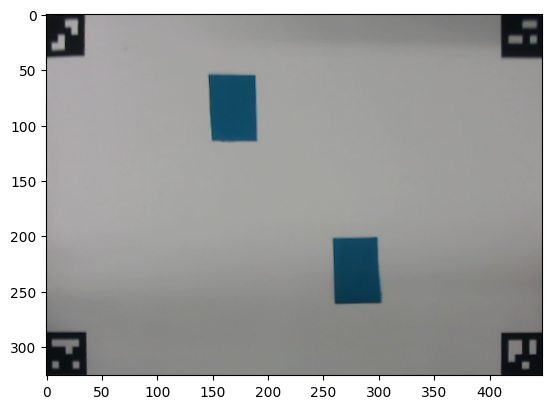

In [ ]:
# Let Camera adjust
cv2.namedWindow("output", cv2.WINDOW_NORMAL)

while True:

    ret, frame = cam.get_frame()

    if not ret:
        print("Error: Could not read frame.")
        break

    cv2.imshow("output", frame)

    if cv2.waitKey(1) & 0xFF == ord('q'):
        break

cv2.destroyAllWindows()

# Print camera stats:
print("Camera fps:", cam.cap.get(cv2.CAP_PROP_FPS))

# Initialize vision
test_frame = vision.setup(frame)
test_frame = cv2.cvtColor(test_frame, cv2.COLOR_BGR2RGB)

plt.imshow(test_frame)
plt.show()

Detect the obstacles and create occupancy grid:

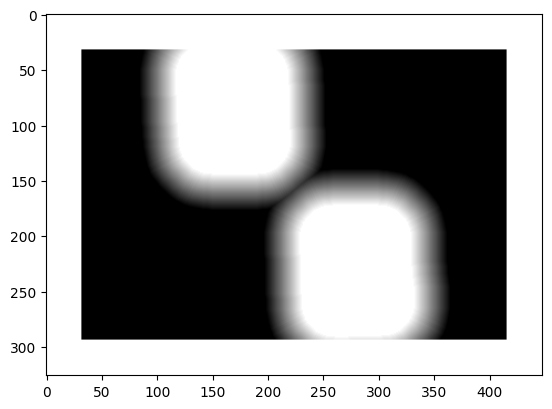

In [ ]:
ret, frame = cam.get_frame()

# Get occupancy grid:
grid = vision.get_occupancy_grid(frame,is_marker_in_corners=True,debug=False)

plt.imshow(grid, cmap="gray")
plt.show()

Initialize Coordinate transforms:

In [ ]:
px_per_cm = vision.pixels_per_cm
px_per_mm = px_per_cm / 10

MAP_HEIGHT_MM = 600
THYMIO_TO_MM_SEC_LEFT = 100 / 29.2 
THYMIO_TO_MM_SEC_RIGHT = 100 / 28.8

tf = CoordinateTransform2D(px_per_mm, MAP_HEIGHT_MM)
speed_t = WheelSpeedTransform(THYMIO_TO_MM_SEC_LEFT, THYMIO_TO_MM_SEC_RIGHT)

Main loop of the robot:

**Ideas:**
- Plot the planned paths only at the end of the loop to avoid lags (plot currently commented)
- Plot ekf covariance elipse also on the cv2 image if it does not overcrowd the visualization
- 

In [ ]:
ekf.clear_history()


try:# Create a window for drawing and start Thymio Client
    cv2.namedWindow("output", cv2.WINDOW_NORMAL)
    thymio = ThymioClient()

    cv2.imshow("output", frame)

    # Hold window until user presses 's' to allow resizing
    while False:
        if cv2.waitKey(1) & 0xFF == ord('q'):
            break

    KIDNAP_THRESH = 200   # Keep at 70 and lift high if black should be ignored
    TIMEOUT_CYCLES = 30

    # Robot State variables
    PLAN_PATH = True
    TIMEOUT = False

    timeout_count = 0
    countdown = 0
    old_left_wheel_speed = 0
    old_right_wheel_speed = 0

    ### Main loop: run until goal is reached
    while True:

        loop_start = time.time()

        # Get a new camera frame:
        ret, frame = cam.get_frame()

        if not ret:
            print("Error: could not read camera frame")
            continue # maybe break

        # Plan a path if necessary:
        if PLAN_PATH:
            print("Plan new path")
            got_loc, pose, _ = vision.localize_robot(frame)
            got_goal, goal_pos = vision.get_goal_position(frame)

            if not got_loc:
                print("Error: could not localize robot during planning")
                continue # maybe break
            if not got_goal:
                print("Error: could not localize goal during planning")
                continue  # maybe break

            # Plan and smooth the path
            path, explored, exporation_count = nav.grid_search_astar(Map=grid, S=pose, G=goal_pos)
            smooth_path = nav.grid_path_smoothing(path=path, Map=grid)
            
            if path is None or len(path) == 0:
                print("Error: could not find a path to the goal")
                continue # maybe break

            # Initialize EKF at robot position
            pose_ekf = tf.vision_to_ekf(pose)
            ekf.init_state(pose_ekf)

            print("Path planned successfully")
            PLAN_PATH = False

        # Get robot sensors:
        prox, v_l, v_r, ground = thymio.get_measurements()

        # Detect Kidnaping:
        if ground[0] < KIDNAP_THRESH and ground[1] < KIDNAP_THRESH and not TIMEOUT:
            # TODO: maybe here wait one tour and measure again if we have false positives
            # -> worked well til now

            print("Robot got kidnaped")
            thymio.set_motors(0, 0)
            
            TIMEOUT = True

        # Drive to target if not in timeout:
        if not TIMEOUT:

            # EKF predict step + visualization:
            v_l_ekf, v_r_ekf = speed_t.thymio_to_mmsec(v_l, v_r)
            ekf.predict(v_r_ekf, v_l_ekf, True)

            # EKF update step:
            got_loc, pose, frame_crop = vision.localize_robot(frame)

            if got_loc:
                pose_ekf = tf.vision_to_ekf(pose)
                ekf.update(pose_ekf, True)
            else:
                ekf.set_empty_measurement()

            ekf_pose, ekf_cov = ekf.get_state_cov()
            ekf_pose_img = tf.ekf_to_vision(ekf_pose)
            
            # Follow the path
            closest_point = nav.find_closest_point_smoothed_path(ekf_pose_img, smooth_path)
            
            if closest_point is None:
                print("Error: no closest point found on path.")
                continue

            ret = nav.target_point(closest_point_on_path=closest_point, look_ahead_distance=10*px_per_cm,
                                    path=smooth_path, return_angles=True)
            target_y_x, angle_segment = ret

            # Calculate and set wheel speeds
            px_per_m = px_per_cm * 100
            target_meters = [target_y_x[1]/px_per_m, target_y_x[0]/px_per_m, angle_segment]
            pose_ekf_img_meters = [ekf_pose_img[0]/px_per_m, ekf_pose_img[1]/px_per_m, ekf_pose_img[2]]
            left_wheel_speed, right_wheel_speed = control.control(robot_pose=pose_ekf_img_meters,
                                                                    goal_pose=target_meters)
            

            condition = (np.array(prox)>2000).any()
            if condition:
                direction_x, direction_y = local_nav.compute(prox, state=True)
                print(f"Local navigation activated: direction_x: {direction_x}, direction_y: {direction_y}")
                gain_x = -10
                gain_global = 40
                left_wheel_speed =  direction_x * gain_x + gain_global + 20 # +20 to avoid getting stuck
                right_wheel_speed =  - direction_x * gain_x + gain_global
                old_left_wheel_speed = left_wheel_speed
                old_right_wheel_speed = right_wheel_speed
                countdown = 50
            
            if countdown > 0 and not condition:
                countdown -= 1
                sens = np.sign(direction_x)
                # if countdown > 30:
                #     left_wheel_speed = sens * 30 + 50
                #     right_wheel_speed = - sens * 30 + 50
                # elif countdown > 10:
                if countdown > 30:
                    left_wheel_speed = 80
                    right_wheel_speed = 80
                elif countdown > 20:
                    left_wheel_speed =  sens * 40 + 50
                    right_wheel_speed = - sens * 40 + 50
                elif countdown > 1:
                    left_wheel_speed = 80
                    right_wheel_speed = 80
                elif countdown == 1:
                    PLAN_PATH = True


            thymio.set_motors(int(right_wheel_speed), int(left_wheel_speed))

        # Handle timeout counter
        else:
            if timeout_count > TIMEOUT_CYCLES:
                TIMEOUT = False
                PLAN_PATH = True
                timeout_count = 0
            else:
                timeout_count += 1
                frame_crop = vision._cut_frame_to_world(frame)
                cv2.putText(frame_crop, f"KIDNAPED!", (155, 280), cv2.FONT_HERSHEY_SIMPLEX, 0.9, (0, 0, 255), 3)

        # Visualize everything # TODO: clean up  
        draw_path(frame_crop, smooth_path, (0, 255, 0))
        draw_point(frame_crop, closest_point, (255, 0, 255))
        draw_pose(frame_crop, ekf_pose_img, (0, 255, 255))
        # draw_covariance(frame_crop, ekf_cov, ekf_pose_img, (0, 255, 255)) j # TODO:
            
        target_x_y = (target_y_x[1], target_y_x[0])
        draw_point(frame_crop, target_x_y, (0, 165, 255))

        distance_to_goal = np.hypot(ekf_pose_img[0] - goal_pos[0], ekf_pose_img[1] - goal_pos[1]) / px_per_cm
        cv2.putText(frame_crop, f"Distance to goal: {distance_to_goal:.2f} cm", (40,30), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (255,255,255), 2)
        # superpose the grid on the frame_crop
        grid_color = cv2.cvtColor(grid, cv2.COLOR_GRAY2BGR)
        grid_color = cv2.resize(grid_color, (frame_crop.shape[1], frame_crop.shape[0]))
        grid_color = cv2.bitwise_not(grid_color)
        transparency = 0.25
        cv2.addWeighted(grid_color, transparency, frame_crop, 1 - transparency, 0, frame_crop)
        
        # Stop the loop if goal is reached
        if cv2.waitKey(1) & 0xFF == ord('q') or distance_to_goal < 2:
            if distance_to_goal < 2:
                cv2.putText(frame_crop, f"GOAL REACHED!", (115, 280), cv2.FONT_HERSHEY_SIMPLEX, 0.9, (0, 255, 0), 3)
                print("Reached goal!")
                cv2.imshow("output", frame_crop)
            break

        cv2.imshow("output", frame_crop)

        # Wait until next iteration
        # loop_delta_t = time.time() - loop_start
        # print(f"Loop delta t: {loop_delta_t}")
        # thymio.wait(D_T)

    ### Once the goal is reached:

    # Stop robot
    thymio.set_motors(0,0)

    # Loop to keep window alive until user closes it
    # TODO: discuss if we want to keep this
    while True:
        if cv2.waitKey(1) & 0xFF == ord('q'):
            break
    cv2.destroyAllWindows()
    thymio.close()
except Exception as e:
    # After the loop stop thymio and close all windows
    cv2.destroyAllWindows()
    thymio.set_motors(0,0)
    thymio.close()
    print("An error occurred:", e)

Client created and connected to Thymio.
Plan new path
Path planned successfully
Reached goal!
Stopping Thymio client and unlocking robot.


Print the EKF stats:

**I want:**
- One plot with the position and covariance ellipses (in EKF frame because plt)
- One errorbar plot with covariance of the heading

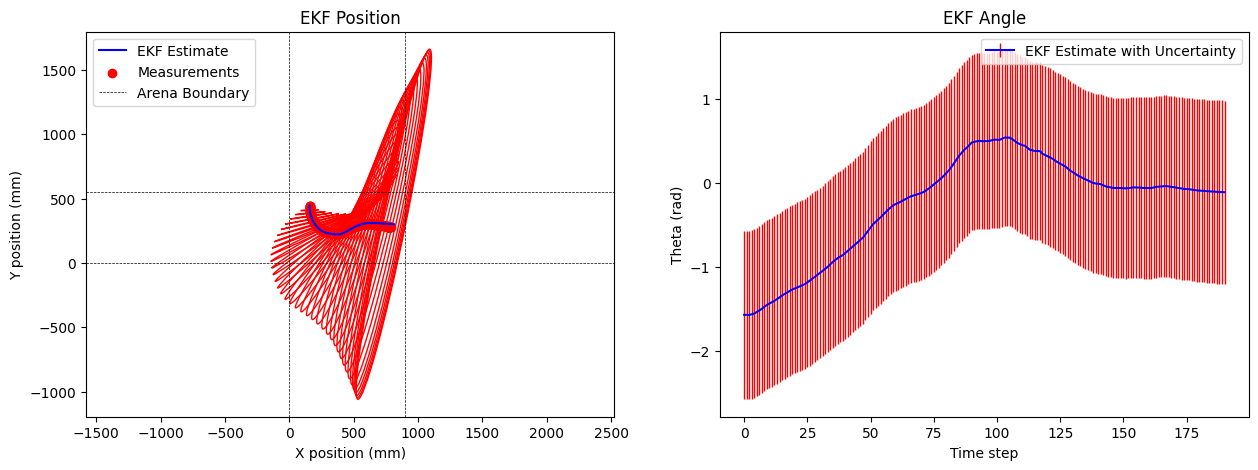

In [ ]:
# Plot the results # TODO: test
history = ekf.get_history()

pose_p, cov_p, pose_u, cov_u, meas, get_p, get_c, v_r, v_l = history

ekf_estimates = np.array(pose_p)
measured_poses = np.array(meas)
measured_poses = measured_poses[~np.all(measured_poses == 0, axis=1)]

get_pos = np.array(get_p)
get_cov = np.array(get_c)

plt.figure(figsize=(15,5))
ax = plt.subplot(1, 2, 1)
plt.plot(get_pos[:,0], get_pos[:,1], label="EKF Estimate", color="blue")
plt.scatter(measured_poses[:,0], measured_poses[:,1], label="Measurements", color="red")
for i, cov in enumerate(get_cov):
    if i%5 == 0:
        plot_covariance_ellipse(get_pos[i][:2], cov[:2, :2], ax, fc="none", ec="red")
plt.xlabel("X position (mm)")
plt.ylabel("Y position (mm)")
plt.axvline(x=0, color='black', linewidth=0.5, ls='--', label="Arena Boundary")
plt.axhline(y=0, color='black', linewidth=0.5, ls='--')
plt.axvline(x=900, color='black', linewidth=0.5, ls='--')
plt.axhline(y=550, color='black', linewidth=0.5, ls='--')
# Set arena limits
plt.title("EKF Position")
plt.legend(loc='upper left')
plt.axis('equal')

plt.subplot(1, 2, 2)
plt.errorbar(range(len(get_pos[:,2])), get_pos[:,2],
             yerr= np.array([np.sqrt(cov[2,2]) for cov in get_cov]),
             label="EKF Estimate with Uncertainty", color="blue", ecolor='red', elinewidth=1, capsize=0)
plt.xlabel("Time step")
plt.ylabel("Theta (rad)")
plt.title("EKF Angle")
plt.legend()

plt.savefig("ekf_results.png")
plt.show()

Shut down the camera thread:

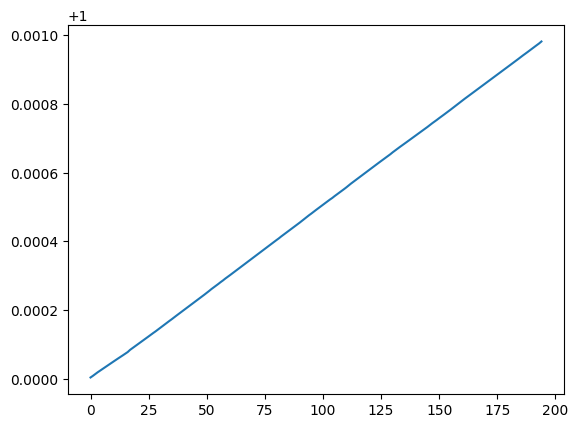

In [ ]:
y = np.array([np.sqrt(cov[2,2]) for cov in get_cov])
plt.plot(range(len(get_pos[:,2])), y)

In [ ]:
cam.stop()

Camera with ID 4 released, thread stopped
